In [ ]:
import sys
import torch
print('=== DIAGNOSTICS ===')
print('Python Executable:', sys.executable)
print('Torch Version:', torch.__version__)
print('CUDA Available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('CUDA Device:', torch.cuda.get_device_name(0))
else:
    import ctypes
    try:
        ctypes.CDLL('nvcuda.dll')
        print('nvcuda.dll loaded successfully via ctypes')
    except Exception as e:
        print('Failed to load nvcuda.dll:', e)


# 2. Baseline CNN
We build a 3-layer Convolutional Neural Network from scratch to establish baseline metrics.

In [4]:
import sys
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report

sys.path.append(str(Path.cwd().parent))

from configs.paths import EUROSAT_DIR, OUTPUTS_DIR
from data.dataset_loader import SatelliteDatasetLoader
from models.baseline_cnn import BaselineCNN
from configs.settings import DEVICE
from training.trainer import Trainer
from lion_pytorch import Lion

# 1. Load Data
loader = SatelliteDatasetLoader(EUROSAT_DIR, split_type='random')
train_loader, val_loader, test_loader = loader.get_dataloaders()
classes = loader.classes
num_classes = len(classes)

2026-07-12 17:22:24,107 - DataLoaders Created. Type: Random
2026-07-12 17:22:24,111 - Train samples: 18900 | Val samples: 4050 | Test samples: 4050


In [5]:
! pip install lion-pytorch

In [6]:
# 2. Initialize Model
model = BaselineCNN(num_classes=num_classes)
criterion = torch.nn.CrossEntropyLoss()
optimizer = Lion(model.parameters(), lr=1e-4,weight_decay=1e-2)

trainer = Trainer(model, criterion, optimizer, device=DEVICE)
save_path = str(OUTPUTS_DIR / 'baseline_cnn_best.pth')

In [7]:
# 3. Train the Model
print("Training Baseline CNN for 10 Epochs...")
history = trainer.train(train_loader, val_loader, epochs=10, save_path=save_path)

2026-07-12 17:22:47,329 - Epoch 1/10


Training Baseline CNN for 10 Epochs...


Training:   0%|          | 0/591 [00:00<?, ?it/s]

2026-07-12 17:34:16,069 - Train Loss: 1.2621 | Train Acc: 0.5449
2026-07-12 17:34:16,070 - Val Loss: 0.7867 | Val Acc: 0.7237 | F1: 0.7039
2026-07-12 17:34:16,117 - -> Saved Best Model Checkpoint to D:\Main Project\outputs\baseline_cnn_best.pth
2026-07-12 17:34:16,118 - Epoch 2/10
2026-07-12 17:45:59,214 - Train Loss: 1.0407 | Train Acc: 0.6342
2026-07-12 17:45:59,215 - Val Loss: 0.6941 | Val Acc: 0.7464 | F1: 0.7284
2026-07-12 17:45:59,233 - -> Saved Best Model Checkpoint to D:\Main Project\outputs\baseline_cnn_best.pth
2026-07-12 17:45:59,234 - Epoch 3/10
2026-07-12 17:57:22,527 - Train Loss: 0.9332 | Train Acc: 0.6728
2026-07-12 17:57:22,527 - Val Loss: 0.6459 | Val Acc: 0.7652 | F1: 0.7488
2026-07-12 17:57:22,546 - -> Saved Best Model Checkpoint to D:\Main Project\outputs\baseline_cnn_best.pth
2026-07-12 17:57:22,547 - Epoch 4/10
2026-07-12 18:08:45,390 - Train Loss: 0.8818 | Train Acc: 0.6920
2026-07-12 18:08:45,391 - Val Loss: 0.6157 | Val Acc: 0.7775 | F1: 0.7659
2026-07-12 18:0

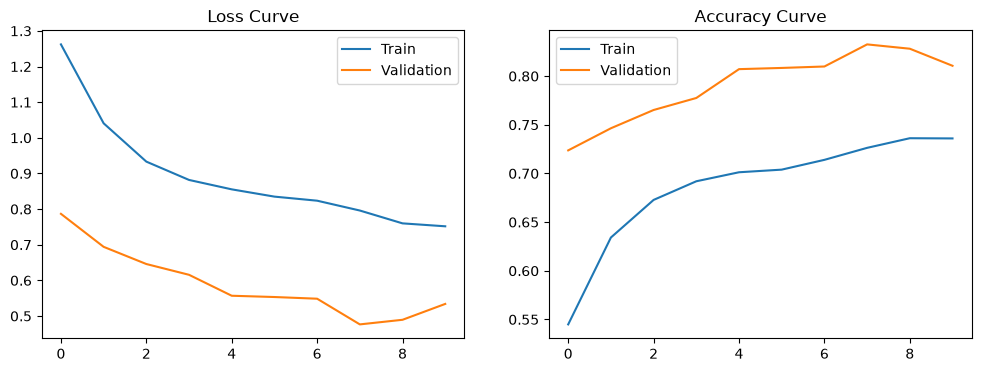

In [8]:
# 4. Plot Training Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history['train_loss'], label='Train')
ax1.plot(history['val_loss'], label='Validation')
ax1.set_title('Loss Curve')
ax1.legend()

ax2.plot(history['train_acc'], label='Train')
ax2.plot(history['val_acc'], label='Validation')
ax2.set_title('Accuracy Curve')
ax2.legend()
plt.show()

Validation Metrics:
Accuracy: 0.8326
Precision: 0.8340
Recall: 0.8266
F1 Score: 0.8221


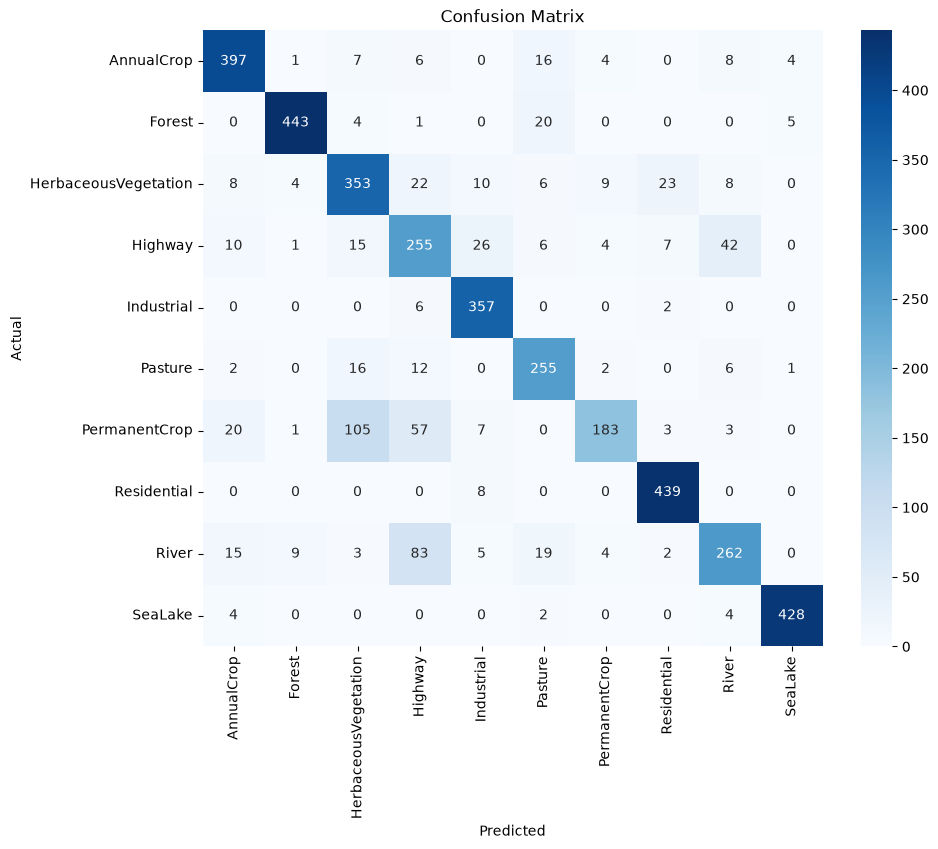

                      precision    recall  f1-score   support

          AnnualCrop       0.87      0.90      0.88       443
              Forest       0.97      0.94      0.95       473
HerbaceousVegetation       0.70      0.80      0.75       443
             Highway       0.58      0.70      0.63       366
          Industrial       0.86      0.98      0.92       365
             Pasture       0.79      0.87      0.83       294
       PermanentCrop       0.89      0.48      0.63       379
         Residential       0.92      0.98      0.95       447
               River       0.79      0.65      0.71       402
             SeaLake       0.98      0.98      0.98       438

            accuracy                           0.83      4050
           macro avg       0.83      0.83      0.82      4050
        weighted avg       0.84      0.83      0.83      4050



In [9]:
# 5. Evaluate on Validation Set
loss, acc, prec, rec, f1, y_true, y_pred = trainer.evaluate(val_loader)

print(f"Validation Metrics:\nAccuracy: {acc:.4f}\nPrecision: {prec:.4f}\nRecall: {rec:.4f}\nF1 Score: {f1:.4f}")

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

print(classification_report(y_true, y_pred, target_names=classes))